# Study 9: fitted per-feature linking functions

What the per-feature Beta-mixture **linking function** looks like for each of the 15 study-9 test
features, for two fits:

- **Part A, current fit** (`results/study9-fit/`): posterior-median ls ≈ 0.98, speaker β ≈ 0.91.
- **Part B, old θ on the preregistered data**: the GP/speaker parameters of the old fit committed in
  `8d87b50` (ls ≈ 0.21, speaker β ≈ 16, the fit with the dramatic-looking coherence field; θ read from
  `fitted-link-shapes-old-beta16.npz`), with the linking shapes **refit to the preregistered ratings**
  at that θ. The old fit itself was run on the pilot data (`data/pilots/study9.csv`), so its saved
  shapes don't belong with the preregistered ratings plotted here.

For feature j in condition c, a rating r is modeled as

    r ~ pz1[c, j] * Beta(a_kl[j], b_kl[j])  +  (1 - pz1[c, j]) * Beta(a_nkl[j], b_nkl[j])

- the **linking shapes** `[a_kl, b_kl, a_nkl, b_nkl]` are fit per feature and shared across conditions
  (`inference.fit_link_shapes`); kl = the higher-mean ("kind-linked") component;
- **pz1** is the ratings-free GP coherence, P(z=1) = P(kind-linked), predicted from each condition's
  training utterances (`inference.prior_pz1_modes`). It is the only thing that differs across conditions.

Nothing is VBMC-refit. Part A loads cached shapes; Part B refits only the linking shapes at the old θ
(`inference.fit_link_shapes`, a few seconds).

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
from matplotlib.lines import Line2D
from scipy.stats import beta as sbeta
from scipy.integrate import quad

import inference as inf

RESULTS_DIR = os.path.join('results', 'study9-fit')
DATA_CSV = '../../data/study9_prereg.csv'

geom = inf.load_geometry()
features = geom['test_feature_names']
trait = geom['test_trait']
J = len(features)

# raw ratings (no half-bin nudge) for plotting; shape fits use the nudged ones, as the pipeline does
responses_cond, _ = inf.load_responses(DATA_CSV, clip_interior=False)
responses_fit, _ = inf.load_responses(DATA_CSV)
R = {c: np.asarray(responses_cond[c]) for c in inf.CONDITIONS}
emp = {c: R[c].mean(0) for c in inf.CONDITIONS}
print({c: R[c].shape[0] for c in inf.CONDITIONS}, "participants per condition")


def load_fit(npz_name, label, refit_shapes=False):
    """theta (+ linking shapes) from a fitted-link-shapes npz, with the ratings-free
    pz1 and predicted mean rating per condition recomputed at that theta.

    refit_shapes=True ignores the saved shapes and refits them to the preregistered
    ratings at this theta (inference.fit_link_shapes, as the pipeline does)."""
    z = np.load(os.path.join(RESULTS_DIR, npz_name), allow_pickle=True)
    assert [str(f) for f in z['feature_names']] == features
    ls, mu0, sig, beta_spk = [float(v) for v in z['theta']]
    pz1 = {c: np.asarray(v) for c, v in inf.prior_pz1_modes(geom, ls, mu0, sig, beta_speaker=beta_spk).items()}
    shapes = inf.fit_link_shapes(responses_fit, pz1) if refit_shapes else np.asarray(z['shapes'])
    a_kl, b_kl, a_nkl, b_nkl = shapes.T
    mean_kl, mean_nkl = a_kl / (a_kl + b_kl), a_nkl / (a_nkl + b_nkl)
    pred = {c: pz1[c] * mean_kl + (1 - pz1[c]) * mean_nkl for c in inf.CONDITIONS}
    print(f"{label}: ls={ls:.3f}  mu_0={mu0:+.3f}  sigma={sig:.3f}  speaker beta={beta_spk:.3f}")
    return dict(label=label, shapes=shapes, theta=(ls, mu0, sig, beta_spk), pz1=pz1, pred=pred,
                a_kl=a_kl, b_kl=b_kl, a_nkl=a_nkl, b_nkl=b_nkl, mean_kl=mean_kl, mean_nkl=mean_nkl)


FIT_NEW = load_fit('fitted-link-shapes.npz', 'current fit')
FIT_OLD = load_fit('fitted-link-shapes-old-beta16.npz', 'old theta, prereg data (speaker beta=16)',
                   refit_shapes=True)

# the current fit's recomputed prediction must match what run_parameter_estimation exported
_csv = pd.read_csv(os.path.join(RESULTS_DIR, 'predictions.csv'))
for c in inf.CONDITIONS:
    exported = _csv[_csv.key == c].set_index('feature').loc[features, 'pred_prior'].values
    assert np.allclose(exported, FIT_NEW['pred'][c], atol=1e-6), c

{'physical': 99, 'diet': 98, 'personality': 103, 'heterogeneous': 101} participants per condition


current fit: ls=0.978  mu_0=+0.006  sigma=0.526  speaker beta=0.907


old theta, prereg data (speaker beta=16): ls=0.205  mu_0=-0.397  sigma=0.782  speaker beta=16.035


In [2]:
# shared plotting setup: one fixed color per condition, reused in every figure
COND_COLOR = {'physical': '#2a78d6', 'diet': '#eb6834',
              'personality': '#1baf7a', 'heterogeneous': '#eda100'}
TEXT_1, TEXT_2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': TEXT_2,
    'xtick.color': TEXT_2, 'ytick.color': TEXT_2,
    'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 8, 'legend.frameon': False,
})

TRAITS = ['diet', 'personality', 'physical']
X = np.linspace(0.005, 0.995, 400)
BINS = np.linspace(0, 1, 21)

def kl_pdf(fit, j):  return sbeta.pdf(X, fit['a_kl'][j], fit['b_kl'][j])
def nkl_pdf(fit, j): return sbeta.pdf(X, fit['a_nkl'][j], fit['b_nkl'][j])
def mix_pdf(fit, j, p): return p * kl_pdf(fit, j) + (1 - p) * nkl_pdf(fit, j)

def ycap(fit, j, hist_max):
    # kl components with a,b < 1 diverge at 0 and 1: cap the axis at the
    # histogram / nkl bump, not at the edge spike
    return 1.25 * max(hist_max, nkl_pdf(fit, j).max(), 1.0)

def style(ax):
    ax.set_xlim(0, 1)
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)


def shapes_table(fit):
    pz1_mat = np.stack([fit['pz1'][c] for c in inf.CONDITIONS])     # (4, J)
    return pd.DataFrame({
        'feature': features, 'trait': trait,
        'a_kl': fit['a_kl'], 'b_kl': fit['b_kl'], 'mean_kl': fit['mean_kl'],
        'a_nkl': fit['a_nkl'], 'b_nkl': fit['b_nkl'], 'mean_nkl': fit['mean_nkl'],
        'kl U-shaped': (fit['a_kl'] < 1) & (fit['b_kl'] < 1),
        'pz1 min': pz1_mat.min(0), 'pz1 max': pz1_mat.max(0),
        'pz1 range': np.ptp(pz1_mat, axis=0),
    }).round(3)


def plot_pooled(fit):
    """3x5 grid: pooled ratings, both components, and each condition's mixture."""
    fig, axes = plt.subplots(3, 5, figsize=(17, 9.5), sharex=True)
    for r, t in enumerate(TRAITS):
        axes[r, 0].set_ylabel(f"{t}\ndensity", color=TEXT_2)
        for k, j in enumerate([j for j in range(J) if trait[j] == t]):
            ax = axes[r, k]
            r_all = np.concatenate([R[c][:, j] for c in inf.CONDITIONS])
            h = ax.hist(r_all, bins=BINS, density=True, color=GRID, edgecolor='white', linewidth=1)[0]
            ax.plot(X, kl_pdf(fit, j),  '--', color='#3d3d3a', lw=1.2, label='kl component')
            ax.plot(X, nkl_pdf(fit, j), '--', color=MUTED,     lw=1.2, label='nkl component')
            for c in inf.CONDITIONS:
                ax.plot(X, mix_pdf(fit, j, fit['pz1'][c][j]), color=COND_COLOR[c], lw=2, label=f'{c} mixture')
            top = ycap(fit, j, h.max())
            for c in inf.CONDITIONS:
                ax.plot([emp[c][j]] * 2, [0, 0.07 * top], color=COND_COLOR[c], lw=2.5, solid_capstyle='round')
            ax.set_ylim(0, top); style(ax)
            ax.set_title(f"{features[j]}\nkl a={fit['a_kl'][j]:.2f} b={fit['b_kl'][j]:.2f} | "
                         f"nkl a={fit['a_nkl'][j]:.2f} b={fit['b_nkl'][j]:.2f}", color=TEXT_1)
    for ax in axes[-1]:
        ax.set_xlabel('rating (prevalence)')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=6, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f"Study 9 linking functions, {fit['label']}: pooled ratings vs per-condition mixtures",
                 y=1.03, fontsize=13)
    fig.tight_layout()
    plt.show()


def plot_per_condition(fit):
    """One figure per trait: rows = features, columns = conditions."""
    for t in TRAITS:
        js = [j for j in range(J) if trait[j] == t]
        fig, axes = plt.subplots(len(js), 4, figsize=(14, 2.3 * len(js)), sharex=True)
        for r, j in enumerate(js):
            tops = []
            for k, c in enumerate(inf.CONDITIONS):
                ax = axes[r, k]
                p, m = fit['pz1'][c][j], fit['pred'][c][j]
                h = ax.hist(R[c][:, j], bins=BINS, density=True, color=GRID, edgecolor='white', linewidth=1)[0]
                ax.plot(X, mix_pdf(fit, j, p), color=COND_COLOR[c], lw=2)
                ax.axvline(emp[c][j], color=TEXT_2, lw=1, ls=':')
                ax.axvline(m, color=COND_COLOR[c], lw=1.2)
                ax.set_title(f"{c}   pz1={p:.3f}   mean emp={emp[c][j]:.2f} / pred={m:.2f}",
                             color=TEXT_1, fontsize=8)
                tops.append(ycap(fit, j, h.max()))
            for k in range(4):
                axes[r, k].set_ylim(0, max(tops)); style(axes[r, k])
            axes[r, 0].set_ylabel(features[j], color=TEXT_2, fontsize=8)
        for ax in axes[-1]:
            ax.set_xlabel('rating (prevalence)')
        fig.suptitle(f"{fit['label']}, {t}: per-condition ratings vs mixture "
                     f"(solid vline = predicted mean, dotted = empirical mean)", fontsize=11)
        fig.tight_layout()
        plt.show()


def plot_dumbbell(fit, ax=None):
    """Component means per feature; predicted (dot) and empirical (diamond) mean per condition."""
    order = [j for t in TRAITS for j in range(J) if trait[j] == t][::-1]
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(10, 8))
    for y, j in enumerate(order):
        ax.plot([fit['mean_nkl'][j], fit['mean_kl'][j]], [y, y], color=GRID, lw=6, solid_capstyle='round', zorder=1)
        ax.plot(fit['mean_nkl'][j], y, 'o', mfc='white', mec=MUTED, ms=8, zorder=2)
        ax.plot(fit['mean_kl'][j],  y, 'o', color=MUTED, ms=8, zorder=2)
        for k, c in enumerate(inf.CONDITIONS):
            dy = (k - 1.5) * 0.14
            ax.plot(fit['pred'][c][j], y + dy, 'o', color=COND_COLOR[c], ms=8, mec='white', mew=1.5, zorder=3)
            ax.plot(emp[c][j], y + dy, 'D', mfc='none', mec=COND_COLOR[c], ms=7, mew=1.6, zorder=3)
    ax.set_yticks(range(J)); ax.set_yticklabels([f"{features[j]}  ({trait[j]})" for j in order])
    for b in (4.5, 9.5):
        ax.axhline(b, color=GRID, lw=1)
    ax.set_xlim(0.15, 0.85); ax.set_xlabel('prevalence')
    ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_title(f"{fit['label']}\ndots = predicted, diamonds = empirical mean per condition",
                 color=TEXT_1, fontsize=11)
    leg = [Line2D([], [], marker='o', ls='', color=COND_COLOR[c], ms=8, label=f'{c} predicted') for c in inf.CONDITIONS]
    leg += [Line2D([], [], marker='D', ls='', mfc='none', mec=TEXT_2, ms=7, label='empirical (condition color)'),
            Line2D([], [], marker='o', ls='', mfc='white', mec=MUTED, ms=8, label='nkl mean'),
            Line2D([], [], marker='o', ls='', color=MUTED, ms=8, label='kl mean')]
    if standalone:
        ax.legend(handles=leg, loc='upper left', bbox_to_anchor=(1.01, 1))
        fig.tight_layout()
        plt.show()
    return leg


def cell_table(fit):
    """Table view of the dumbbell numbers (color is the only identity cue in the plot)."""
    rows = [{'feature': features[j], 'trait': trait[j], 'condition': c,
             'pred_mean': fit['pred'][c][j], 'emp_mean': emp[c][j]}
            for j in range(J) for c in inf.CONDITIONS]
    return pd.DataFrame(rows).pivot_table(index=['trait', 'feature'], columns='condition',
                                          values=['pred_mean', 'emp_mean']).round(3)


def check_mixtures(fit):
    """Each mixture density integrates to ~1; the mixture mean equals the prediction."""
    worst_int, worst_pred = 0.0, 0.0
    for j in range(J):
        for c in inf.CONDITIONS:
            p = fit['pz1'][c][j]
            f = lambda x: p * sbeta.pdf(x, fit['a_kl'][j], fit['b_kl'][j]) + (1 - p) * sbeta.pdf(x, fit['a_nkl'][j], fit['b_nkl'][j])
            worst_int = max(worst_int, abs(quad(f, 0, 1, limit=200)[0] - 1))   # quad copes with the edge spikes
            m = p * fit['mean_kl'][j] + (1 - p) * fit['mean_nkl'][j]
            worst_pred = max(worst_pred, abs(m - fit['pred'][c][j]))
    print(f"{fit['label']}: max |mixture mass - 1| = {worst_int:.2e},  max |mixture mean - pred| = {worst_pred:.2e}")
    assert worst_int < 1e-3 and worst_pred < 1e-4

# Part A: current fit

## A1. Linking shapes per feature

`kl U-shaped` flags components with a < 1 and b < 1: density piles up at 0 **and** 1 instead of
forming a bump. `pz1 range` is the spread of the coherence across the 4 conditions, which is all the
room the GP has to move a feature's predicted rating.

In [3]:
shapes_table(FIT_NEW)

,feature,trait,a_kl,b_kl,mean_kl,a_nkl,b_nkl,mean_nkl,kl U-shaped,pz1 min,pz1 max,pz1 range
0,can eat spicy food,diet,0.836,0.362,0.698,4.233,3.796,0.527,True,0.564,0.574,0.010
1,eat breakfast very late,diet,0.561,0.337,0.624,2.618,5.442,0.325,True,0.565,0.574,0.009
2,eat five meals a day,diet,0.622,0.354,0.637,1.513,2.329,0.394,True,0.564,0.574,0.010
3,like juice with pulp,diet,0.748,0.386,0.660,4.716,4.569,0.508,True,0.565,0.575,0.010
4,put pepper on all their foods,diet,0.520,0.352,0.596,1.593,2.316,0.408,True,0.563,0.574,0.011
5,cry easily,personality,0.616,0.398,0.607,2.630,4.353,0.377,True,0.569,0.574,0.005
6,like to collect rocks,personality,0.635,0.328,0.659,1.470,2.935,0.334,True,0.567,0.574,0.007
7,like to dance,personality,1.040,0.290,0.782,5.681,3.175,0.641,False,0.570,0.574,0.004
8,like to give high-fives,personality,0.794,0.284,0.737,4.711,2.283,0.674,True,0.568,0.574,0.007
9,like to read books,personality,0.942,0.305,0.755,5.509,3.983,0.580,True,0.568,0.574,0.007


## A2. All conditions pooled

Grey bars: that feature's ratings pooled over all participants. Dashed: the two linking components
(dark = kl, light = nkl). Colored: the mixture each condition predicts, using its own pz1. Ticks
along the bottom are each condition's **empirical** mean rating.

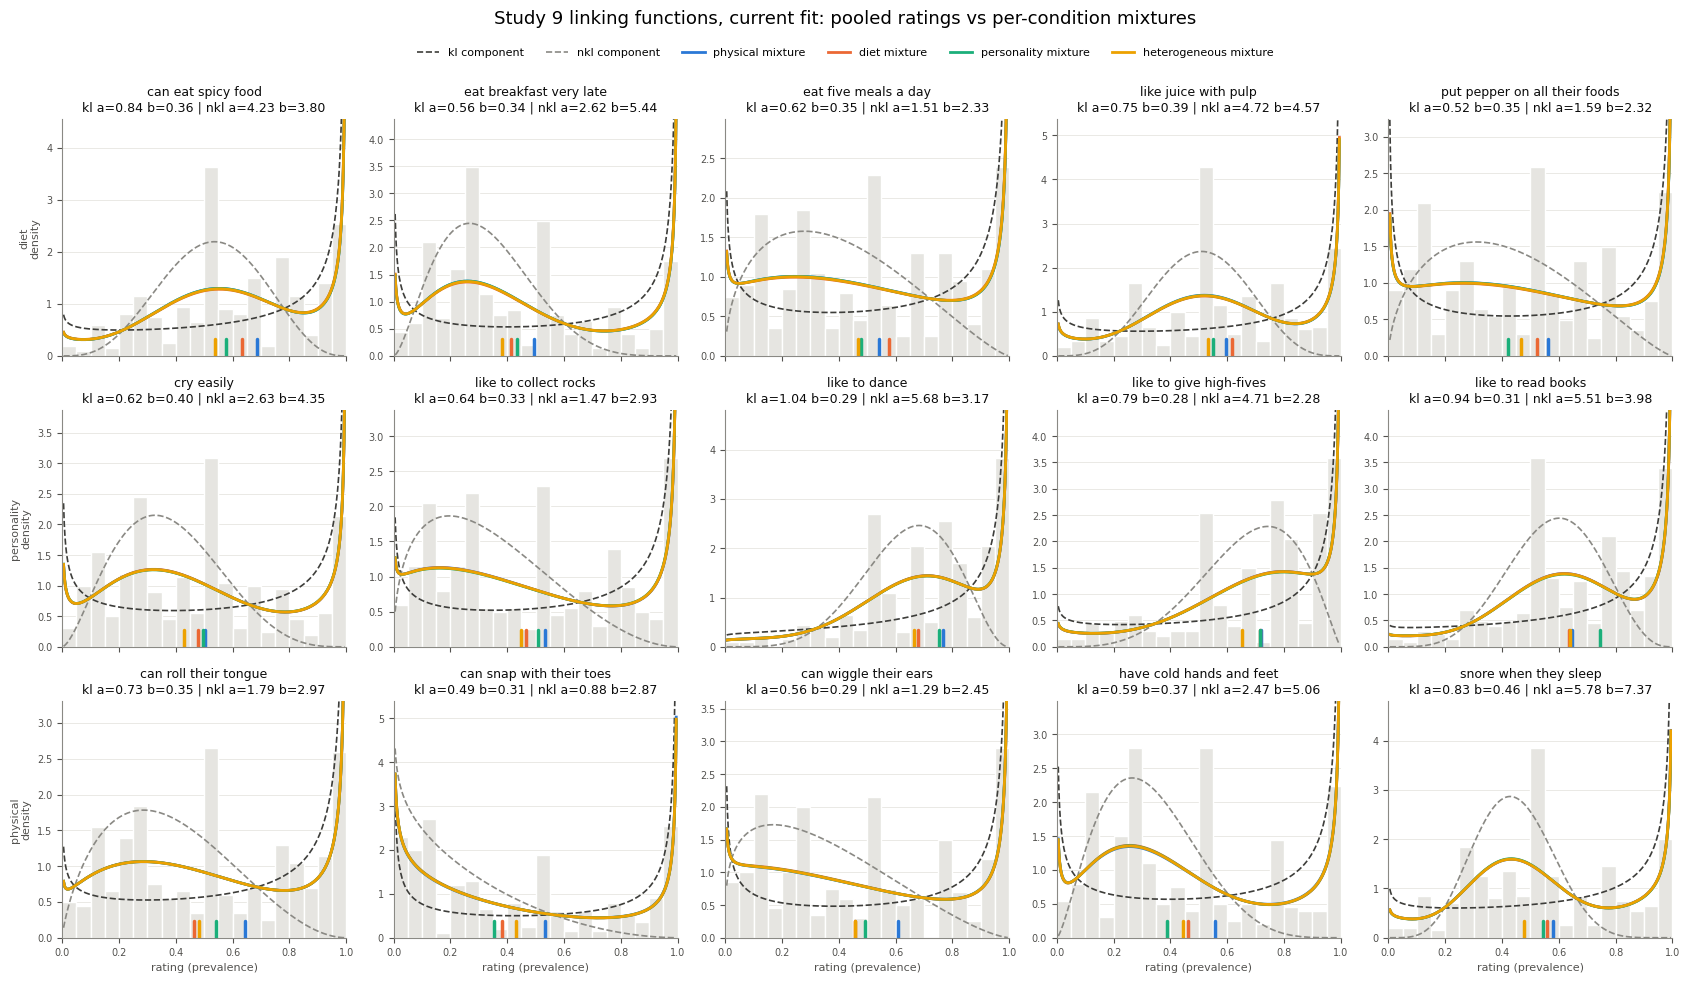

In [4]:
plot_pooled(FIT_NEW)

## A3. Per condition

Each column is one condition: its own participants' ratings (bars) against its own mixture (line).
The components are the same in every column; only the mixture weight pz1 (in each panel title) changes.
One figure per trait, 5 features × 4 conditions.

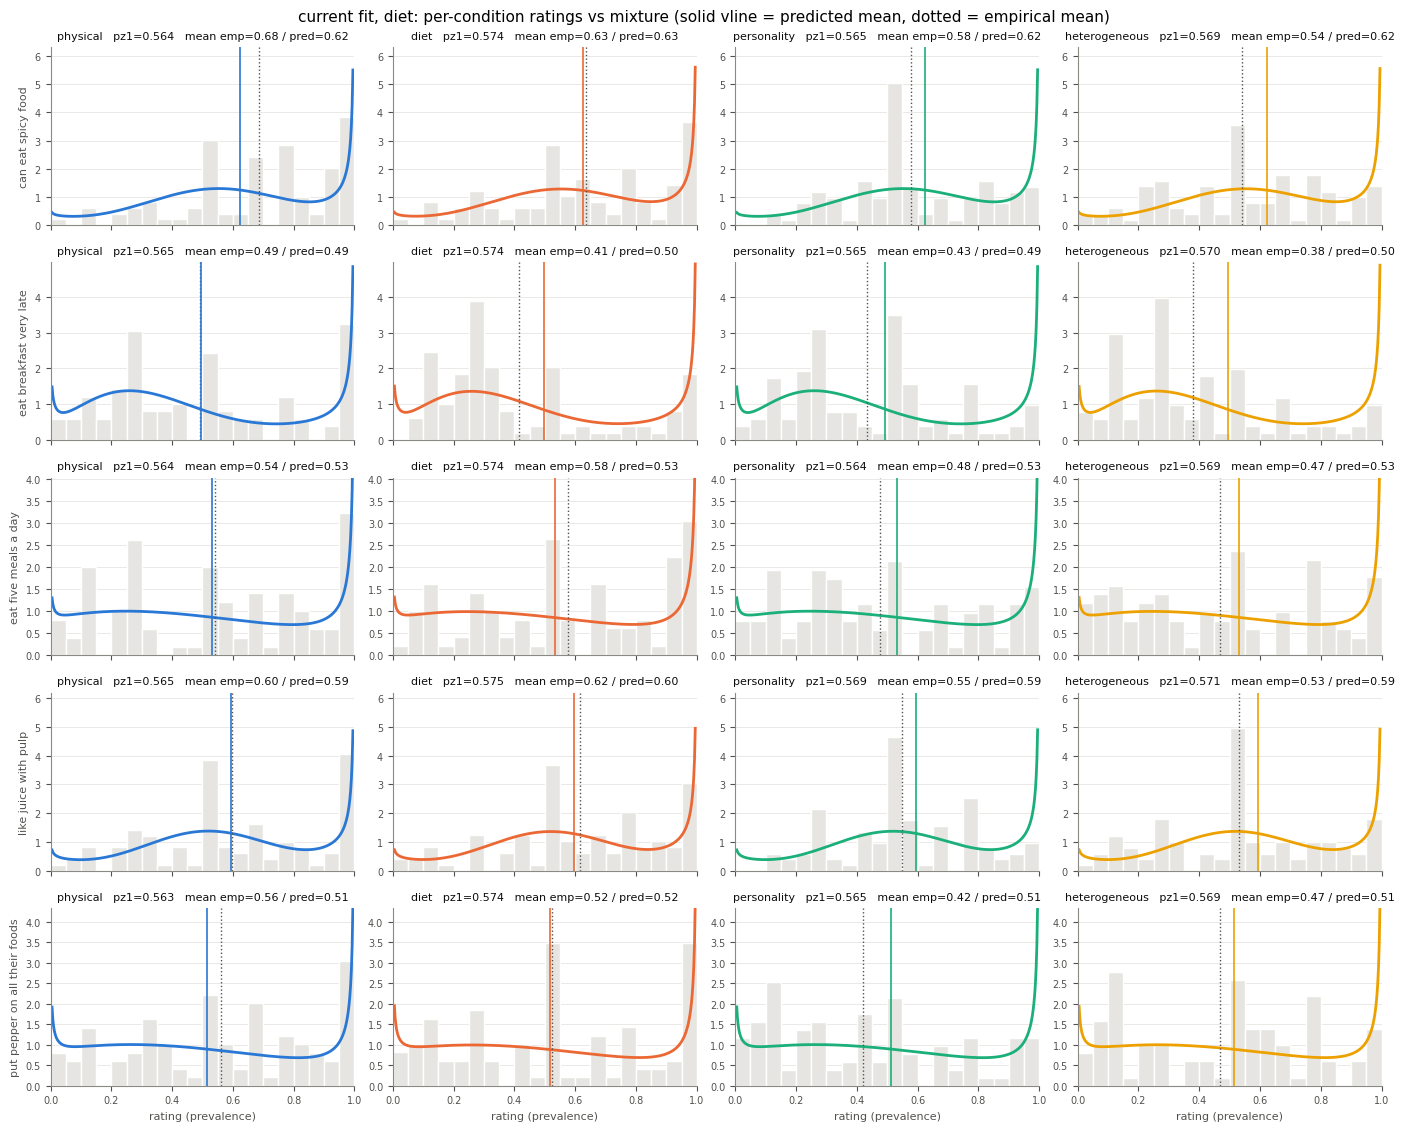

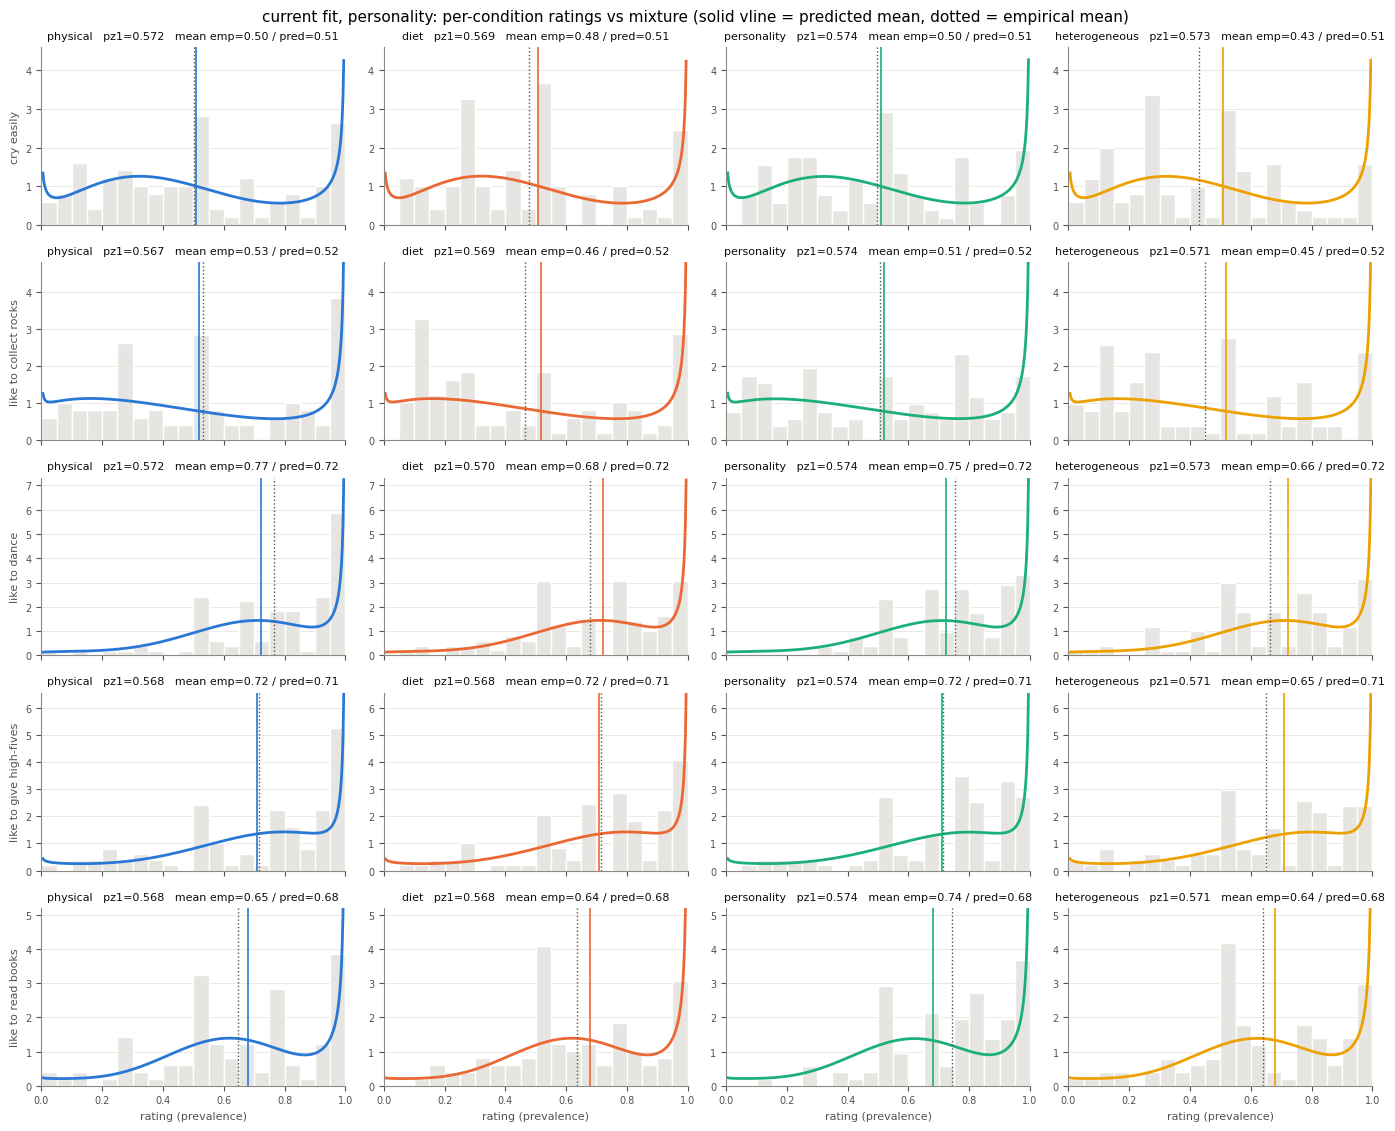

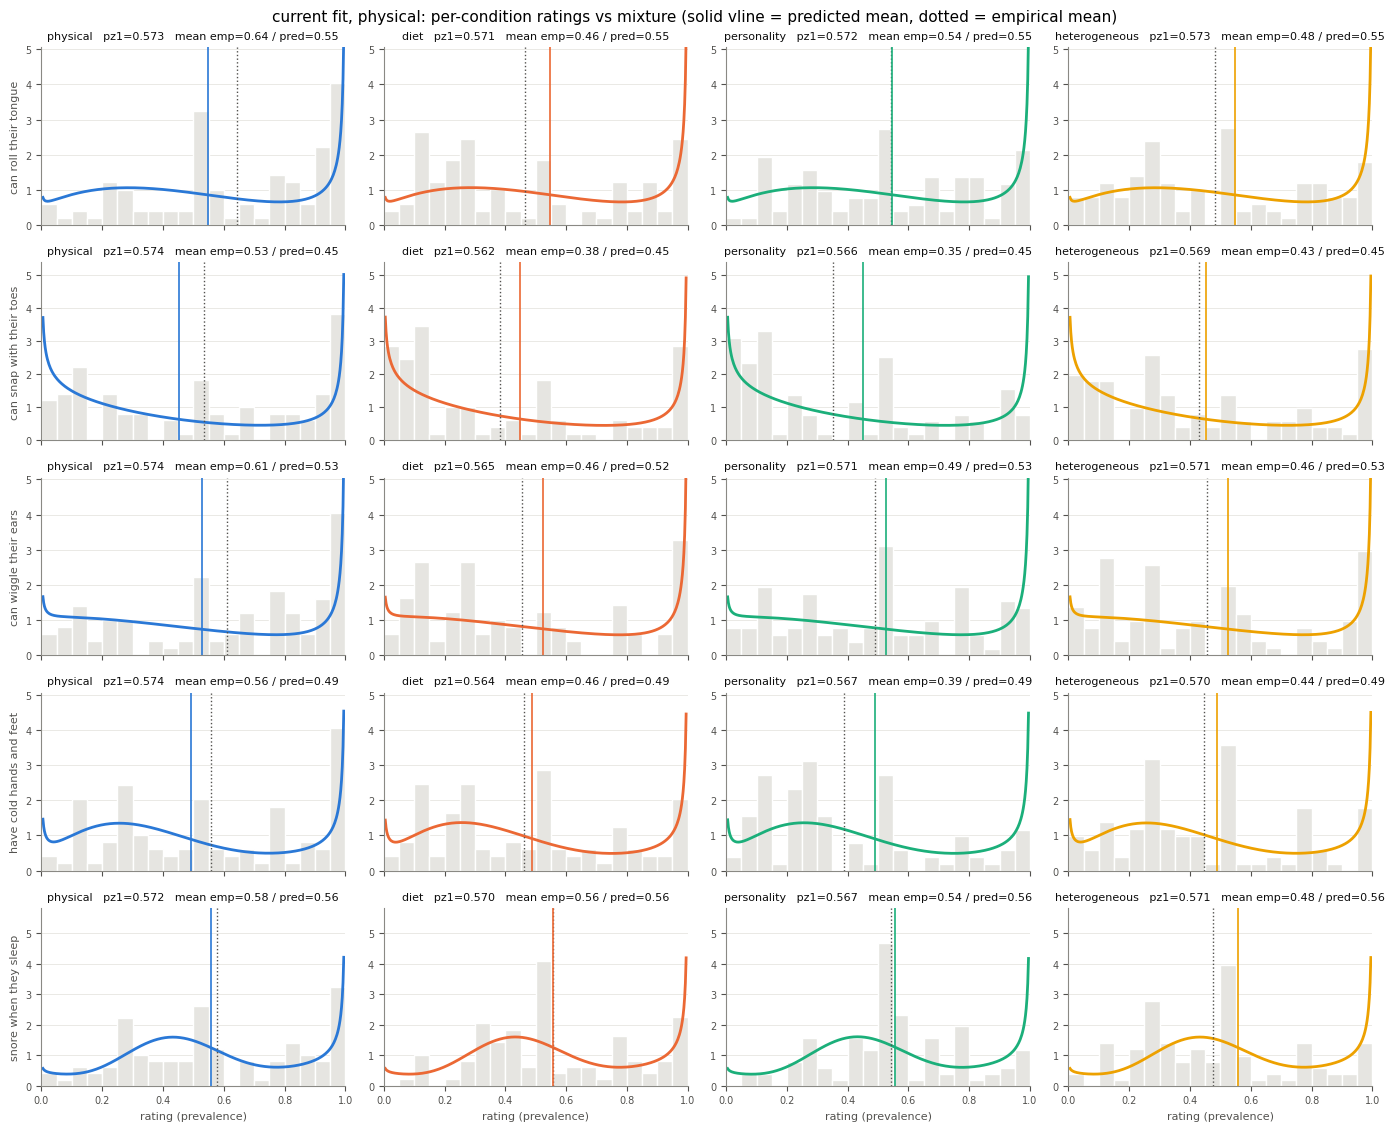

In [5]:
plot_per_condition(FIT_NEW)

## A4. What the linking function fixes vs what coherence can move

For each feature the grey bar spans the two component means (nkl ○ to kl ●). A condition's predicted
mean always sits on that bar at `pz1*mean_kl + (1-pz1)*mean_nkl`, so the **bar's position** is set by
the linking function and **where along it** each condition lands is set by the coherence field.
Filled dots = predicted mean per condition; hollow diamonds = empirical mean.

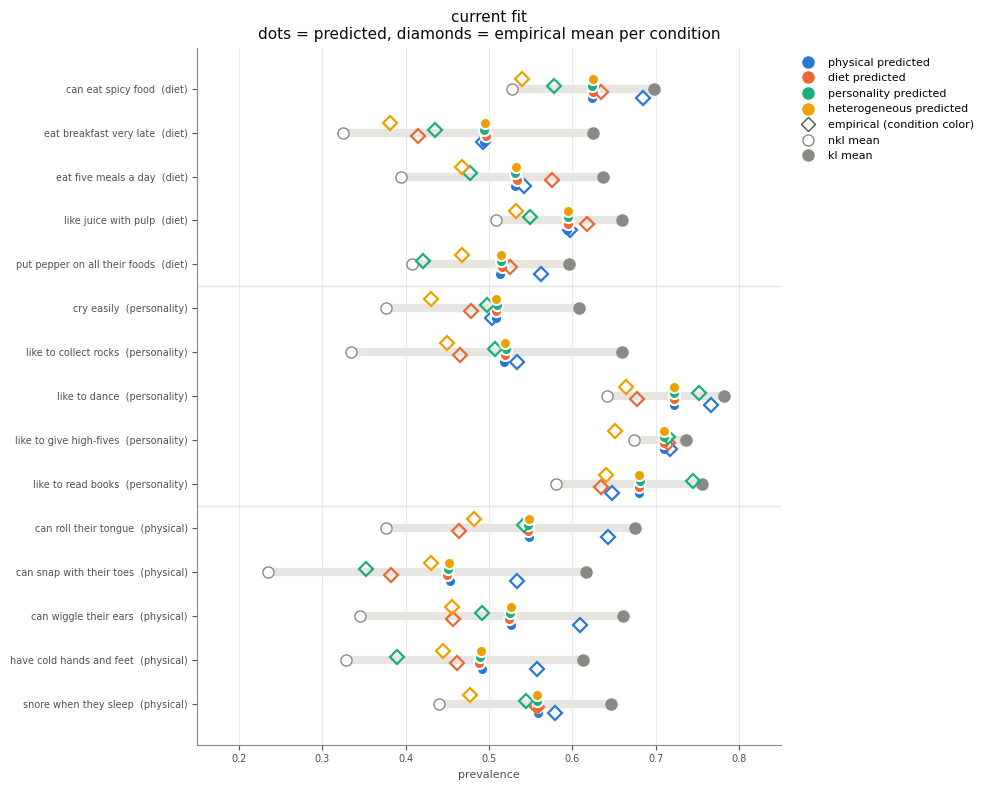

In [6]:
plot_dumbbell(FIT_NEW);

In [7]:
cell_table(FIT_NEW)

emp_mean                            \
condition                                     diet heterogeneous personality   
trait       feature                                                            
diet        can eat spicy food               0.634         0.540       0.578   
            eat breakfast very late          0.414         0.381       0.435   
            eat five meals a day             0.576         0.467       0.477   
            like juice with pulp             0.617         0.532       0.549   
            put pepper on all their foods    0.525         0.468       0.421   
personality cry easily                       0.478         0.430       0.498   
            like to collect rocks            0.465         0.449       0.508   
            like to dance                    0.678         0.664       0.753   
            like to give high-fives          0.715         0.651       0.715   
            like to read books               0.635         0.641       0.744   
physical    can roll their tongue            0.464         0.482       0.542   
            can snap with their toes         0.383         0.430       0.352   
            can wiggle their ears            0.456         0.456       0.491   
            have cold hands and feet         0.462         0.445       0.389   
            snore when they sleep            0.557         0.477       0.544   

                                                   pred_mean                \
condition                                 physical      diet heterogeneous   
trait       feature                                                          
diet        can eat spicy food               0.685     0.625         0.624   
            eat breakfast very late          0.492     0.497         0.496   
            eat five meals a day             0.542     0.533         0.532   
            like juice with pulp             0.597     0.595         0.595   
            put pepper on all their foods    0.563     0.516         0.515   
personality cry easily                       0.504     0.508         0.509   
            like to collect rocks            0.533     0.519         0.520   
            like to dance                    0.766     0.721         0.722   
            like to give high-fives          0.718     0.710         0.710   
            like to read books               0.647     0.680         0.680   
physical    can roll their tongue            0.643     0.547         0.548   
            can snap with their toes         0.534     0.449         0.451   
            can wiggle their ears            0.609     0.524         0.526   
            have cold hands and feet         0.558     0.488         0.490   
            snore when they sleep            0.579     0.558         0.558   

                                                                
condition                                 personality physical  
trait       feature                                             
diet        can eat spicy food                  0.624    0.624  
            eat breakfast very late             0.494    0.494  
            eat five meals a day                0.531    0.531  
            like juice with pulp                0.594    0.594  
            put pepper on all their foods       0.514    0.514  
personality cry easily                          0.509    0.509  
            like to collect rocks               0.521    0.518  
            like to dance                       0.722    0.722  
            like to give high-fives             0.710    0.709  
            like to read books                  0.681    0.680  
physical    can roll their tongue               0.547    0.547  
            can snap with their toes            0.450    0.453  
            can wiggle their ears               0.526    0.527  
            have cold hands and feet            0.489    0.491  
            snore when they sleep               0.557    0.558

## A5. What to look for

- **U-shaped kl components.** In 14 of 15 features the kl component has a, b < 1, so "kind-linked" puts
  mass at both extremes rather than forming a high-prevalence bump (the exception, "like to dance",
  has a = 1.04: J-shaped, still piled up at 1). Its mean (~0.6–0.8) is only modestly above the nkl mean.
- **nkl carries the feature identity.** The nkl means range from ~0.23 to ~0.67 across features, and
  the bars in A4 sit at very different places. That spread is the feature-level variance the
  linking function takes up.
- **Coherence barely moves anything.** pz1 sits at ~0.56-0.58 for every feature in every condition
  (`pz1 range` <= 0.012 in A1), so the four mixture curves in A2 lie on top of each other
  and the colored dots in A4 land at almost the same point. The condition differences in the
  data (the diamonds, up to ~0.2 apart) are not captured.

# Part B: old θ (speaker β ≈ 16, ls ≈ 0.21) on the preregistered data

θ = (ls, μ₀, σ, speaker β) from the old fit (`8d87b50`); pz1 computed at that θ; linking shapes refit to
the preregistered ratings at that θ. So Part A and Part B differ **only in θ**: same data, same code.

Why refit: the old fit was run on the pilot data (`data/pilots/study9.csv`, 101/101/101/99 per condition)
rather than the preregistered data (99/98/103/101). Checked: the old code (`8d87b50`) and the current code
give identical pz1 at this θ and reproduce the saved old shapes exactly on the pilot data, so the
condition-order change and the refactor had no effect; only the data differs.

Note the old θ was itself *fit* to the pilot data, so here it is a fixed setting of the parameters,
not a fit to these data.

## B0. Optimizer check: pilot-fit shapes vs the prereg refit

Negative interval log-likelihood per feature (lower = better) on the preregistered ratings, at the old θ,
for the saved pilot-fit shapes vs the shapes just refit to these ratings. The refit should always win.
A negative `NLL pilot − refit` means the fitter's four starting points missed a better optimum (the
pilot shapes are a valid point it could have reached).

In [8]:
from model_jax import _neg_ll_one_feature

pilot_shapes = np.load(os.path.join(RESULTS_DIR, 'fitted-link-shapes-old-beta16.npz'))['shapes']
R_fit  = np.concatenate([np.asarray(responses_fit[c]) for c in inf.CONDITIONS])
TH_fit = np.concatenate([np.tile(FIT_OLD['pz1'][c], (responses_fit[c].shape[0], 1)) for c in inf.CONDITIONS])
b0 = pd.DataFrame({
    'feature': features,
    'NLL pilot shapes': [_neg_ll_one_feature(np.log(pilot_shapes[j]),       R_fit[:, j], TH_fit[:, j]) for j in range(J)],
    'NLL prereg refit': [_neg_ll_one_feature(np.log(FIT_OLD['shapes'][j]), R_fit[:, j], TH_fit[:, j]) for j in range(J)],
})
b0['NLL pilot − refit'] = b0['NLL pilot shapes'] - b0['NLL prereg refit']
b0.round(2)

,feature,NLL pilot shapes,NLL prereg refit,NLL pilot − refit
0,can eat spicy food,1756.38,1755.38,1.00
1,eat breakfast very late,1789.73,1786.21,3.52
2,eat five meals a day,1792.98,1791.82,1.16
3,like juice with pulp,1771.85,1770.45,1.40
4,put pepper on all their foods,1797.60,1795.93,1.67
5,cry easily,1803.28,1815.93,-12.65
6,like to collect rocks,1782.39,1786.91,-4.53
7,like to dance,1664.31,1659.43,4.88
8,like to give high-fives,1695.51,1706.50,-10.99
9,like to read books,1699.67,1693.31,6.36


## B1. Linking shapes per feature

In [9]:
shapes_table(FIT_OLD)

,feature,trait,a_kl,b_kl,mean_kl,a_nkl,b_nkl,mean_nkl,kl U-shaped,pz1 min,pz1 max,pz1 range
0,can eat spicy food,diet,0.814,0.355,0.696,4.049,3.509,0.536,True,0.420,0.729,0.310
1,eat breakfast very late,diet,0.592,0.363,0.620,2.735,5.934,0.316,True,0.424,0.726,0.303
2,eat five meals a day,diet,0.618,0.346,0.641,1.444,2.170,0.400,True,0.418,0.723,0.305
3,like juice with pulp,diet,0.774,0.401,0.659,4.657,4.611,0.502,True,0.441,0.769,0.328
4,put pepper on all their foods,diet,0.527,0.351,0.601,1.470,2.150,0.406,True,0.420,0.737,0.317
5,cry easily,personality,0.496,0.242,0.673,2.034,3.099,0.396,True,0.476,0.754,0.278
6,like to collect rocks,personality,0.560,0.219,0.719,1.248,2.043,0.379,True,0.476,0.742,0.266
7,like to dance,personality,1.146,0.338,0.772,6.133,3.572,0.632,False,0.504,0.738,0.234
8,like to give high-fives,personality,0.643,0.185,0.776,3.145,1.630,0.659,True,0.460,0.761,0.301
9,like to read books,personality,1.017,0.331,0.755,5.885,4.565,0.563,False,0.463,0.758,0.294


## B2. All conditions pooled

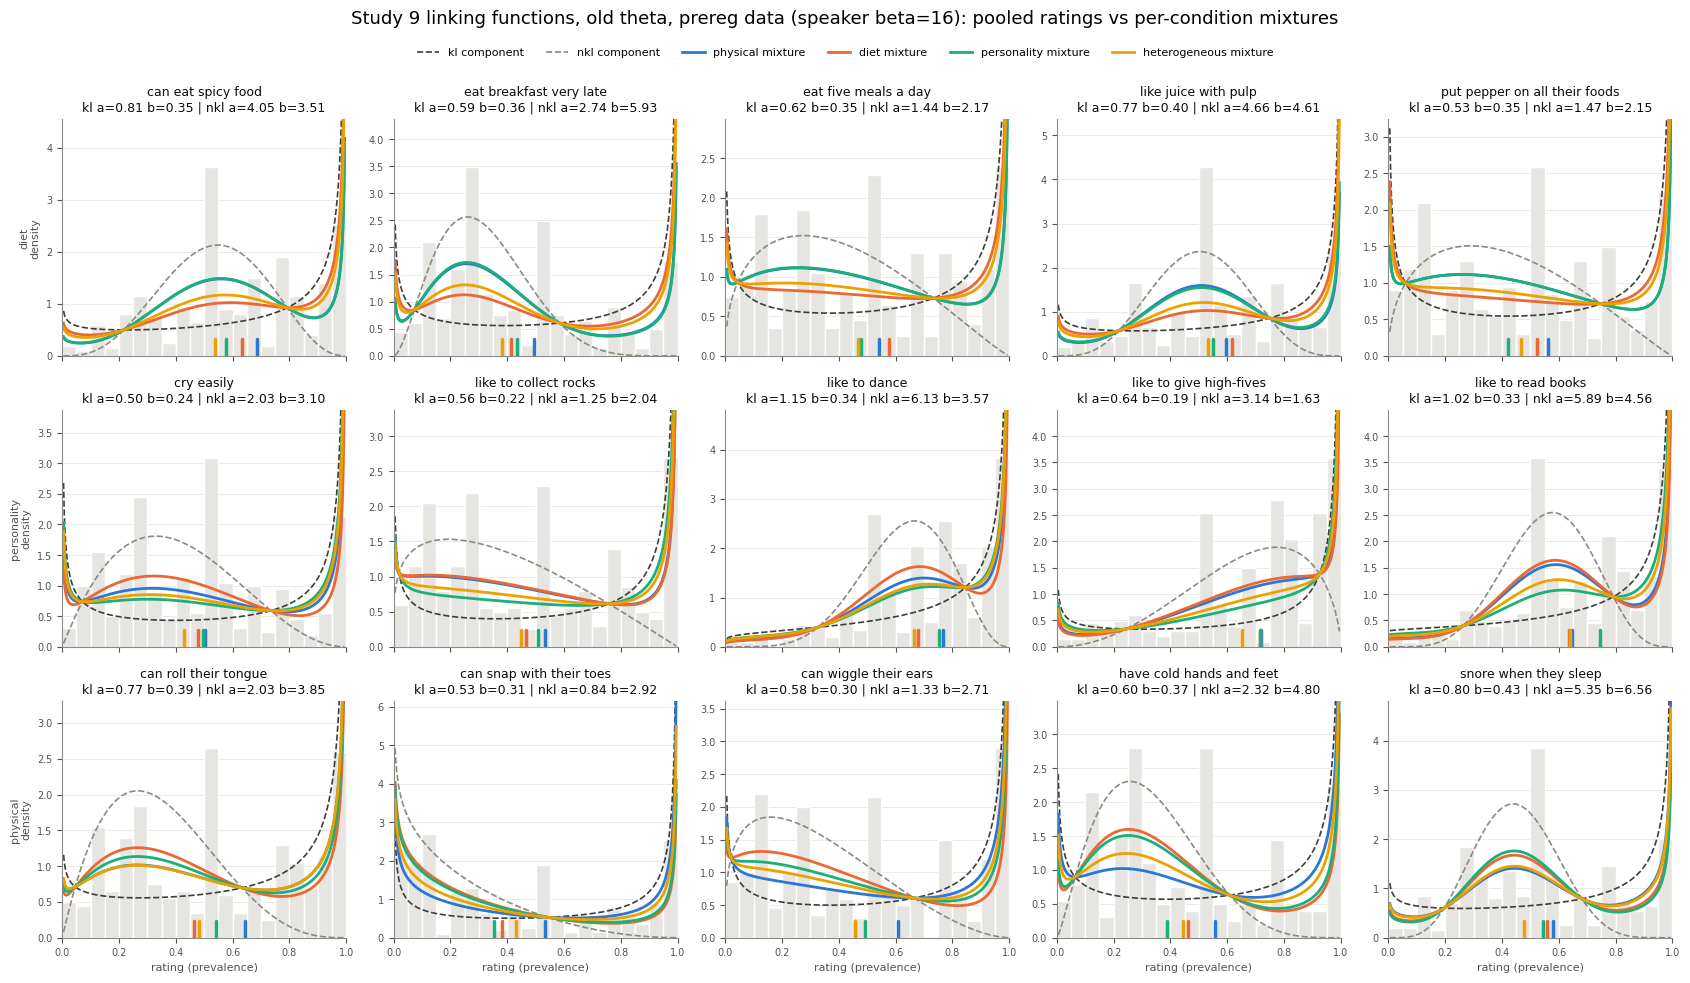

In [10]:
plot_pooled(FIT_OLD)

## B3. Per condition

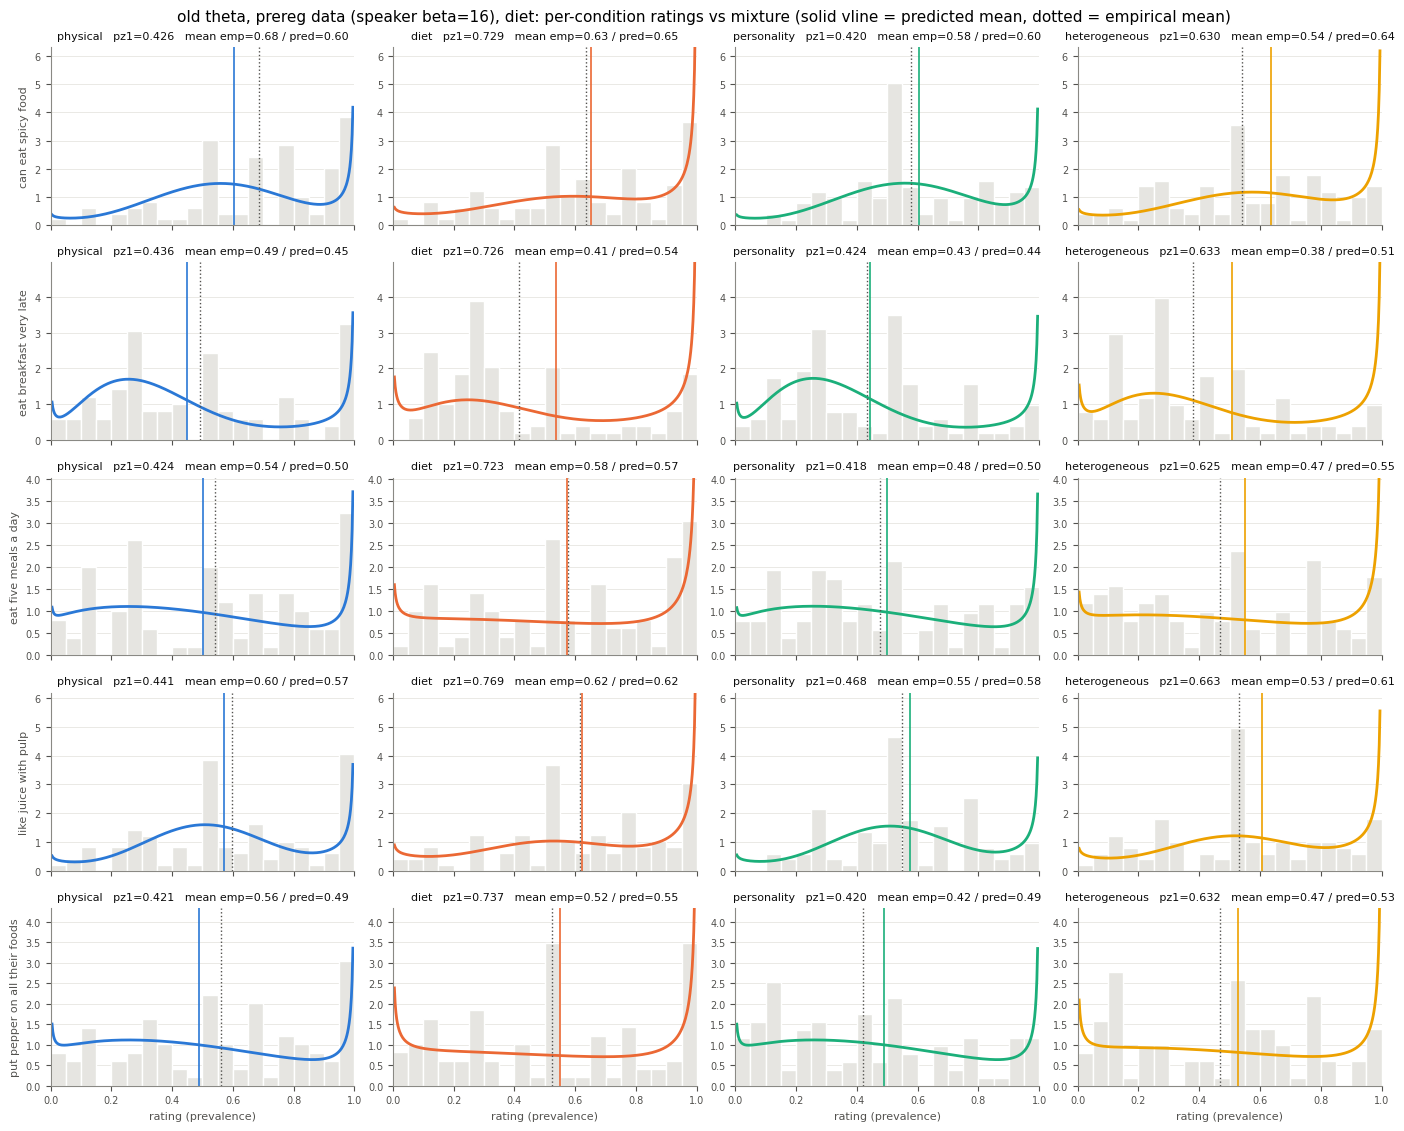

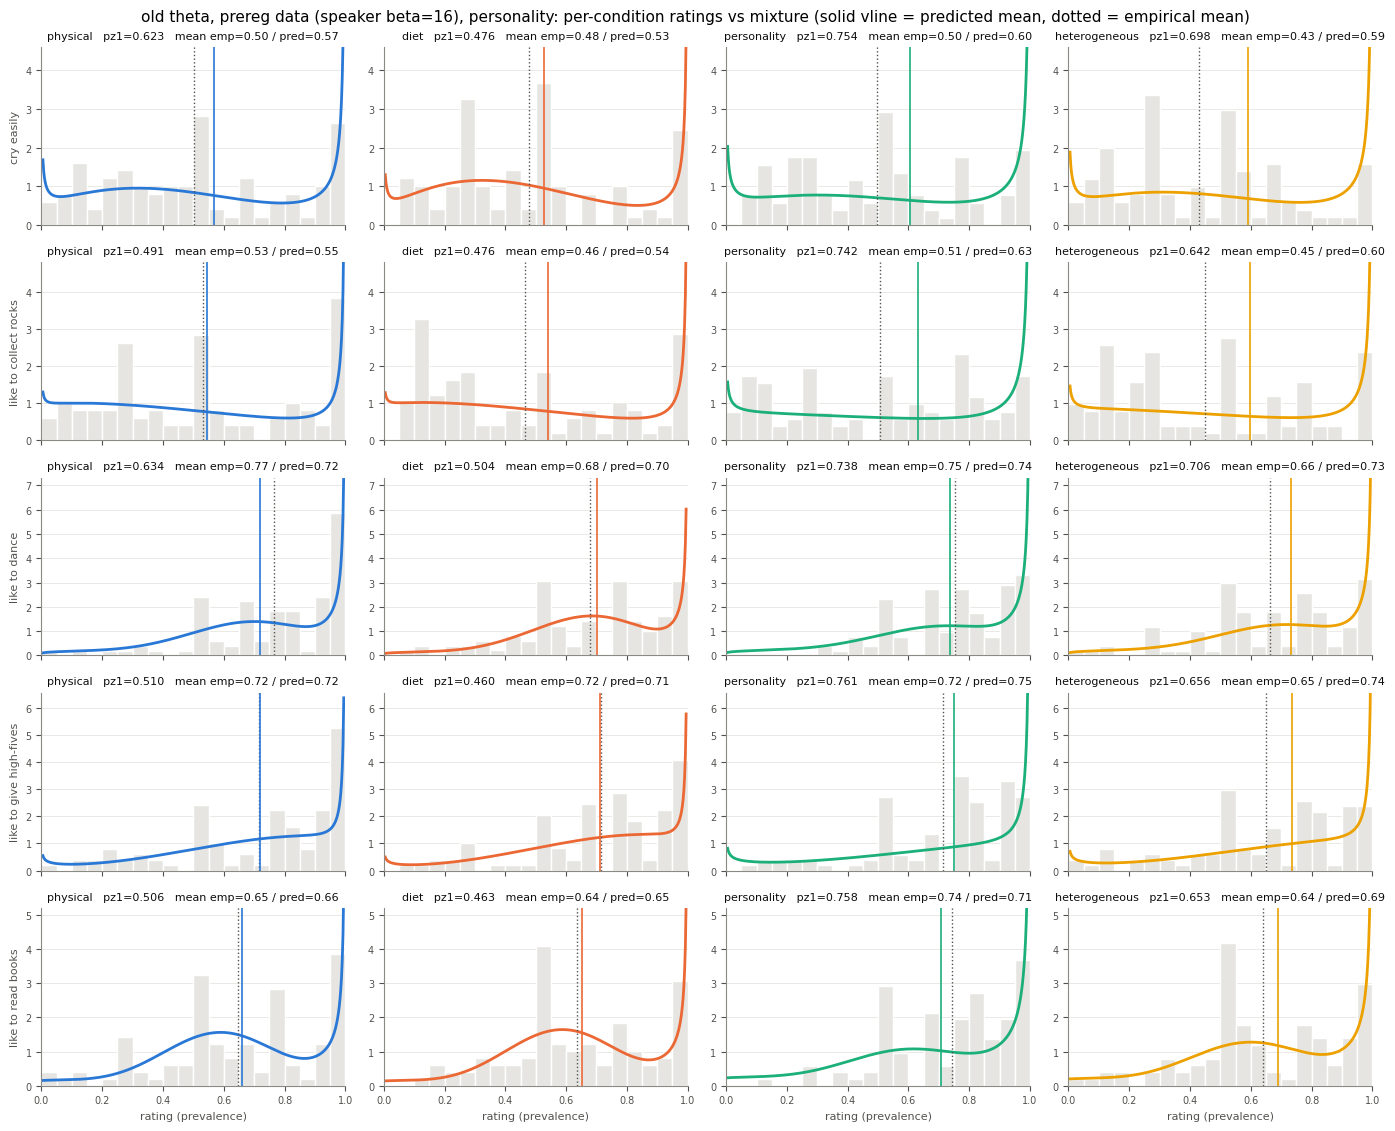

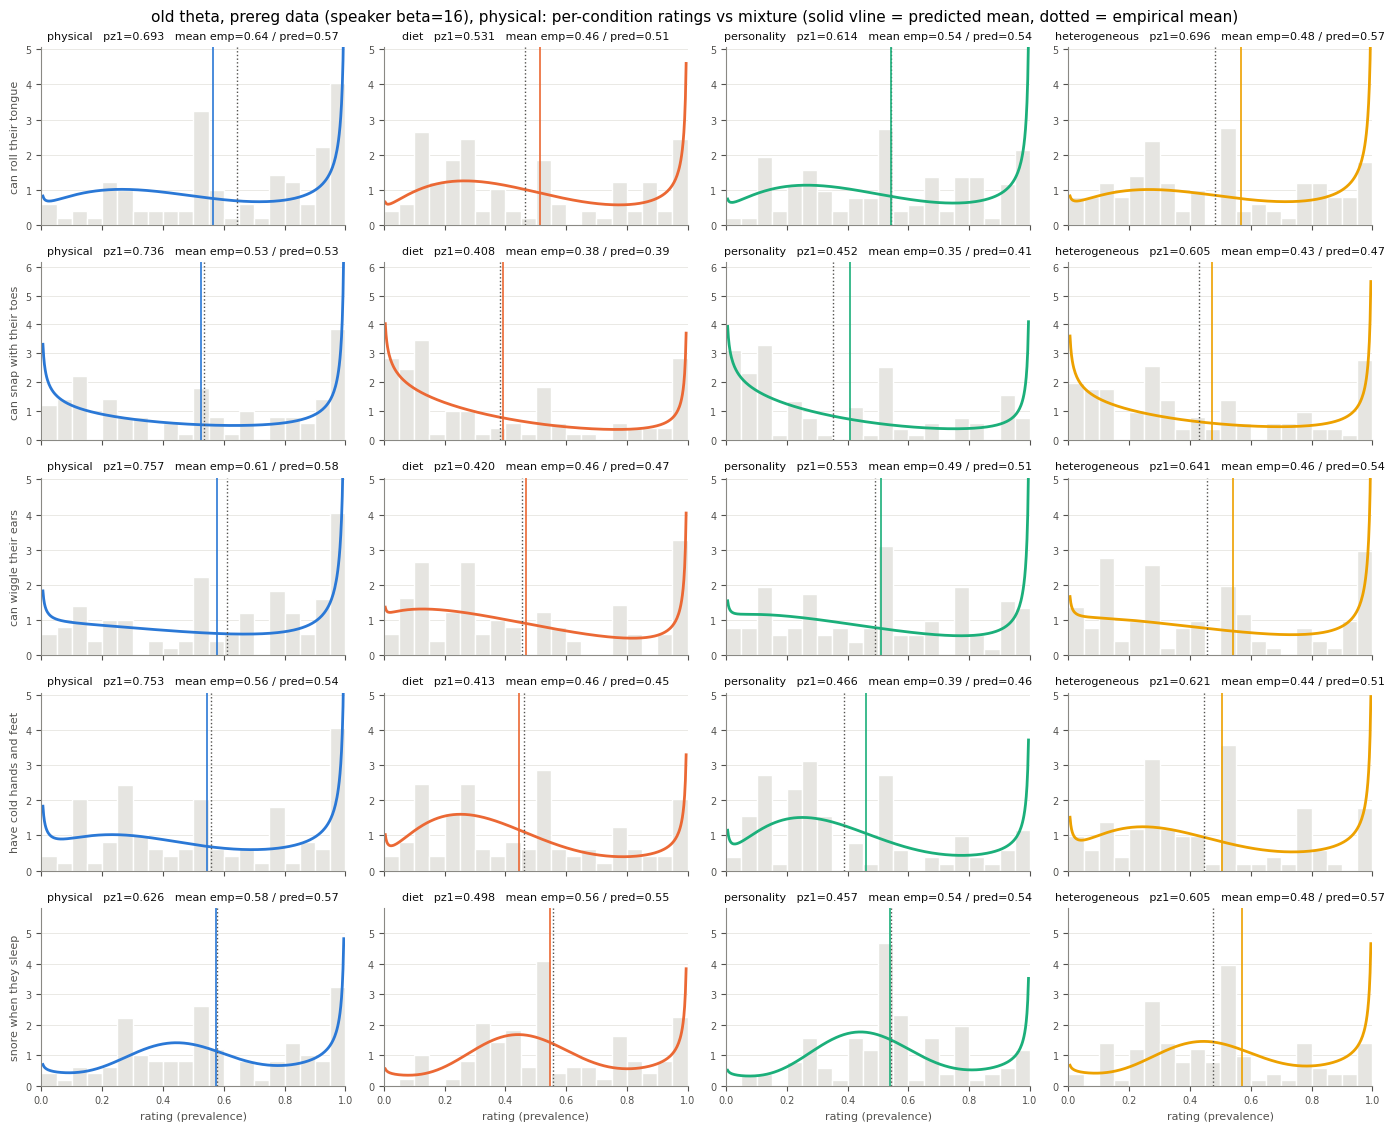

In [11]:
plot_per_condition(FIT_OLD)

## B4. What the linking function fixes vs what coherence can move

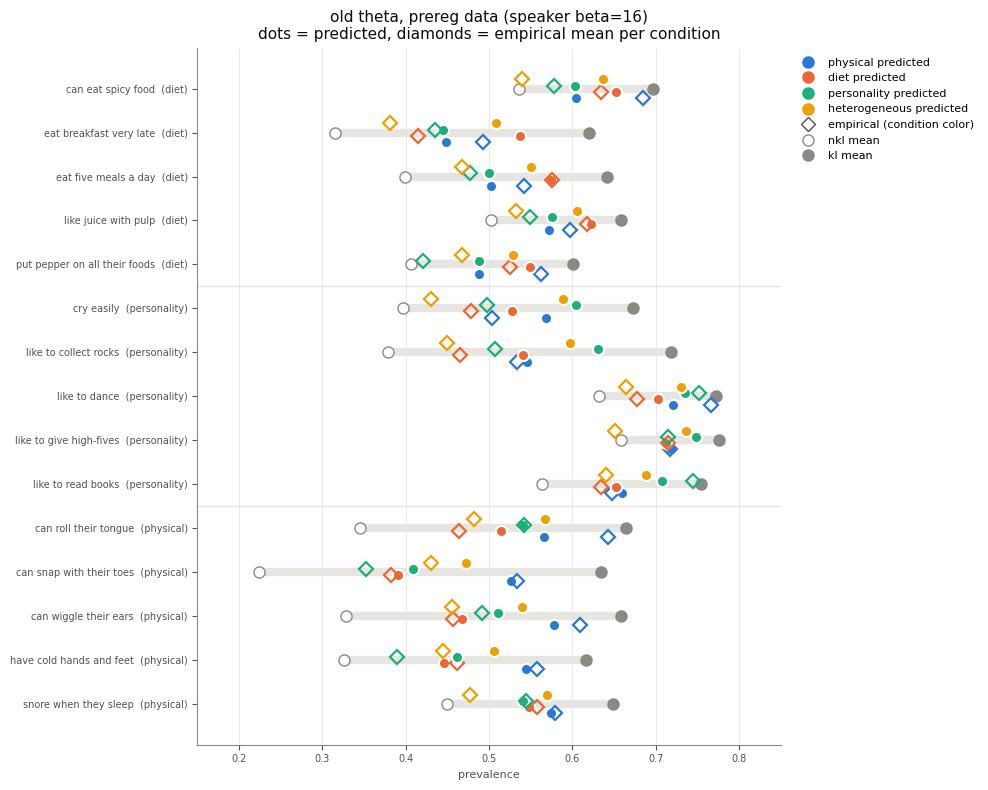

In [12]:
plot_dumbbell(FIT_OLD);

In [13]:
cell_table(FIT_OLD)

emp_mean                            \
condition                                     diet heterogeneous personality   
trait       feature                                                            
diet        can eat spicy food               0.634         0.540       0.578   
            eat breakfast very late          0.414         0.381       0.435   
            eat five meals a day             0.576         0.467       0.477   
            like juice with pulp             0.617         0.532       0.549   
            put pepper on all their foods    0.525         0.468       0.421   
personality cry easily                       0.478         0.430       0.498   
            like to collect rocks            0.465         0.449       0.508   
            like to dance                    0.678         0.664       0.753   
            like to give high-fives          0.715         0.651       0.715   
            like to read books               0.635         0.641       0.744   
physical    can roll their tongue            0.464         0.482       0.542   
            can snap with their toes         0.383         0.430       0.352   
            can wiggle their ears            0.456         0.456       0.491   
            have cold hands and feet         0.462         0.445       0.389   
            snore when they sleep            0.557         0.477       0.544   

                                                   pred_mean                \
condition                                 physical      diet heterogeneous   
trait       feature                                                          
diet        can eat spicy food               0.685     0.653         0.637   
            eat breakfast very late          0.492     0.537         0.508   
            eat five meals a day             0.542     0.574         0.550   
            like juice with pulp             0.597     0.623         0.606   
            put pepper on all their foods    0.563     0.550         0.529   
personality cry easily                       0.504     0.528         0.589   
            like to collect rocks            0.533     0.541         0.597   
            like to dance                    0.766     0.703         0.731   
            like to give high-fives          0.718     0.713         0.736   
            like to read books               0.647     0.652         0.688   
physical    can roll their tongue            0.643     0.515         0.567   
            can snap with their toes         0.534     0.391         0.472   
            can wiggle their ears            0.609     0.467         0.540   
            have cold hands and feet         0.558     0.446         0.506   
            snore when they sleep            0.579     0.548         0.570   

                                                                
condition                                 personality physical  
trait       feature                                             
diet        can eat spicy food                  0.603    0.604  
            eat breakfast very late             0.445    0.448  
            eat five meals a day                0.500    0.502  
            like juice with pulp                0.576    0.571  
            put pepper on all their foods       0.488    0.488  
personality cry easily                          0.605    0.568  
            like to collect rocks               0.631    0.546  
            like to dance                       0.735    0.721  
            like to give high-fives             0.748    0.719  
            like to read books                  0.708    0.660  
physical    can roll their tongue               0.541    0.566  
            can snap with their toes            0.409    0.526  
            can wiggle their ears               0.511    0.579  
            have cold hands and feet            0.461    0.544  
            snore when they sleep               0.540    0.574

# Part C: current vs old side by side

Left/right: the A4 and B4 summaries on the same axes. Below: how far pz1 moves across conditions in each
fit, and how well each fit's predicted means track the empirical means over the 60 condition × feature
cells, both overall and **within feature** (each feature's across-condition mean removed from both, so
only the condition effects remain: the part that only the coherence field can explain).

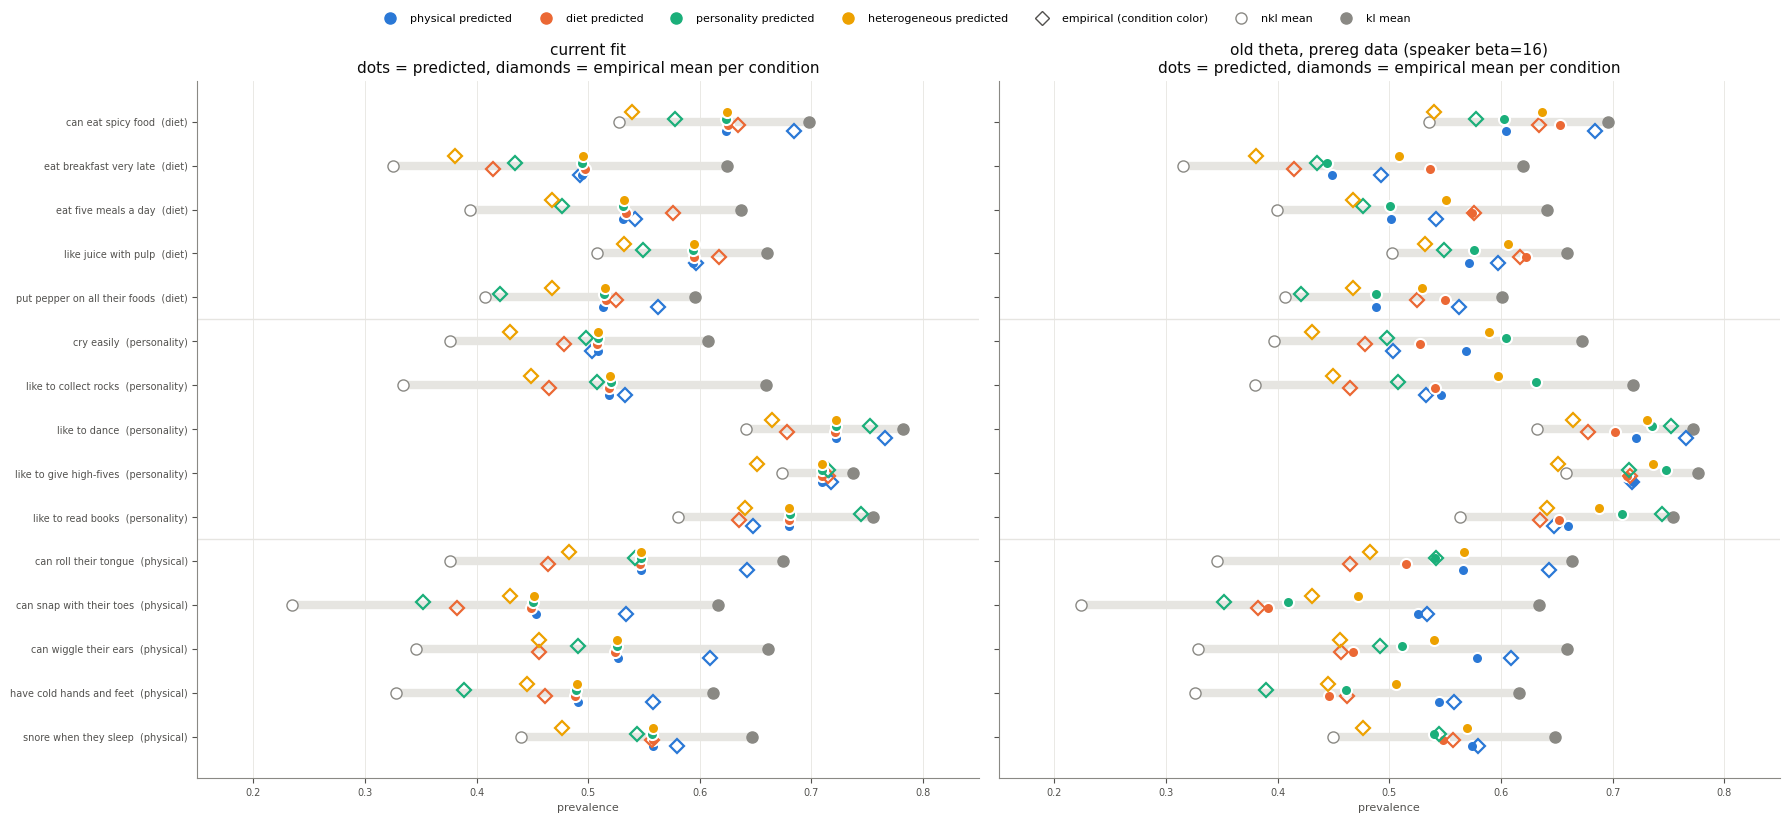

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)
leg = plot_dumbbell(FIT_NEW, axes[0])
plot_dumbbell(FIT_OLD, axes[1])
fig.legend(handles=leg, loc='upper center', ncol=7, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
plt.show()

In [15]:
def fit_summary(fit):
    P = np.stack([fit['pred'][c] for c in inf.CONDITIONS])     # (4, J)
    E = np.stack([emp[c] for c in inf.CONDITIONS])
    Z = np.stack([fit['pz1'][c] for c in inf.CONDITIONS])
    r2 = lambda p, e: 1 - np.sum((e - p) ** 2) / np.sum((e - e.mean()) ** 2)
    Pw, Ew = P - P.mean(0), E - E.mean(0)                        # within-feature (condition effects)
    ls, mu0, sig, b = fit['theta']
    return {'fit': fit['label'], 'ls': ls, 'speaker beta': b,
            'pz1 min': Z.min(), 'pz1 max': Z.max(), 'mean pz1 range / feature': np.ptp(Z, axis=0).mean(),
            'r overall': np.corrcoef(P.ravel(), E.ravel())[0, 1], 'R2 overall': r2(P.ravel(), E.ravel()),
            'r within-feature': np.corrcoef(Pw.ravel(), Ew.ravel())[0, 1], 'R2 within-feature': r2(Pw.ravel(), Ew.ravel())}

pd.DataFrame([fit_summary(FIT_NEW), fit_summary(FIT_OLD)]).set_index('fit').round(3).T

fit,current fit,"old theta, prereg data (speaker beta=16)"
ls,0.978,0.205
speaker beta,0.907,16.035
pz1 min,0.562,0.408
pz1 max,0.575,0.769
mean pz1 range / feature,0.008,0.285
r overall,0.872,0.847
R2 overall,0.705,0.626
r within-feature,0.347,0.363
R2 within-feature,0.011,0.066


## What to look for

Same data and same code in both columns; only θ differs.

- **At the old θ the field moves pz1 a lot** (~0.41 to ~0.77, a range of ~0.29 per feature vs ~0.01 at
  the current θ), and in the expected direction: each single-category condition raises coherence for its
  own trait's features (diet condition → diet features, etc.), and heterogeneous sits in between.
- **But it tracks the data's condition effects barely better.** Within-feature R² goes from ~0.01 to
  ~0.07, and overall R² drops (~0.70 → ~0.63). The main mismatch is visible in the right panel: the old θ
  puts **heterogeneous** (yellow) high for most features, while empirically heterogeneous is often the
  *lowest* condition (yellow diamonds on the left).
- **The linking shapes look much the same under both θ.** kl is U-shaped in 13–14 of 15 features, and the
  nkl means still carry the feature identity, so with either coherence field the between-feature
  variance comes from the linking function.

## Sanity checks

In [16]:
check_mixtures(FIT_NEW)
check_mixtures(FIT_OLD)

current fit: max |mixture mass - 1| = 4.98e-09,  max |mixture mean - pred| = 0.00e+00
old theta, prereg data (speaker beta=16): max |mixture mass - 1| = 3.65e-09,  max |mixture mean - pred| = 0.00e+00
